# Task 4 (Medium) - Trend Prediction Analysis
- **Description:** Analyzing historical content trends and forecast future content growth.

## Step 1: Prepare release-year data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_theme(style="whitegrid")

data = pd.read_csv("Cleaned_Netflix_Dataset.csv")

# Number of titles per release year
yearly = data["release_year"].value_counts().sort_index()
yearly.tail(10)

release_year
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64

In [3]:
# 2021 is incomplete (the data ends in September 2021), so it is left out of modelling.
# Years before 2005 have very few titles, so the model uses 2005-2020.
series = yearly.loc[2005:2020]
print("Years used:", series.index.min(), "-", series.index.max())
print("2021 titles (partial year):", yearly.loc[2021])

Years used: 2005 - 2020
2021 titles (partial year): 592


## Step 2: Analyzing yearly content trends

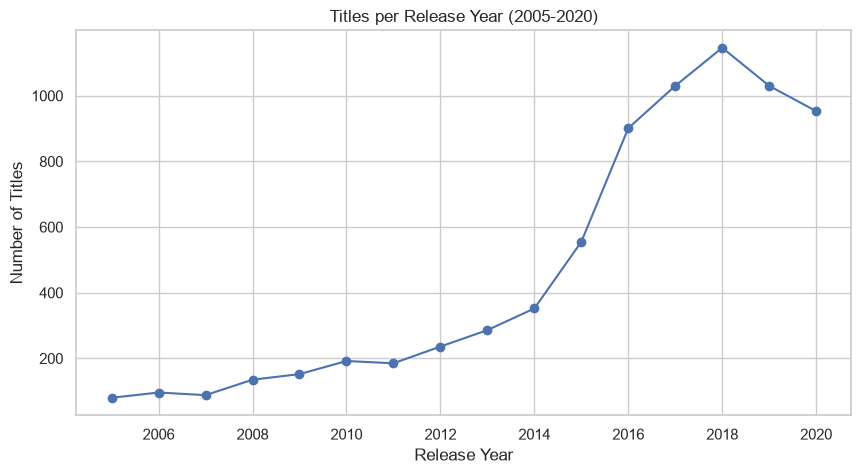

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(series.index, series.values, marker="o")
plt.title("Titles per Release Year (2005-2020)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

In [6]:
trend = pd.DataFrame({"titles": series, "growth_%": (series.pct_change() * 100).round(1)})
print("Peak year:", series.idxmax(), "with", series.max(), "titles")
trend.tail(8)

Peak year: 2018 with 1146 titles


,titles,growth_%
release_year,,
2013,286,21.2
2014,352,23.1
2015,555,57.7
2016,901,62.3
2017,1030,14.3
2018,1146,11.3
2019,1030,-10.1
2020,953,-7.5


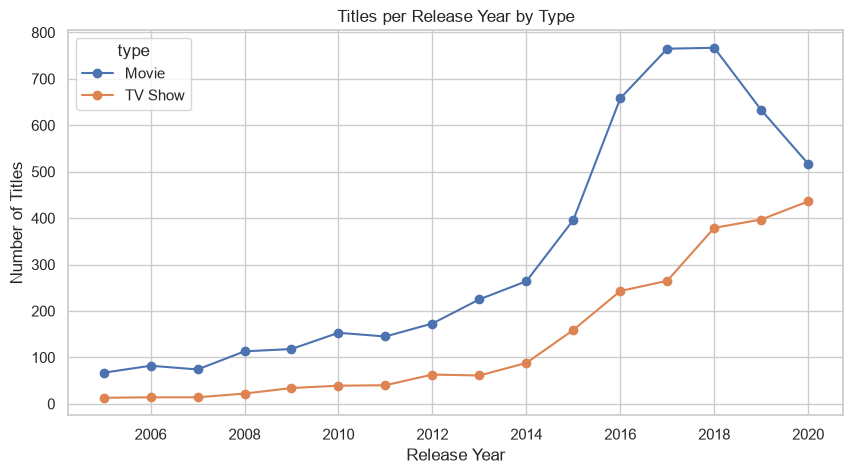

In [7]:
# Movies vs TV Shows by release year
by_type = data[data["release_year"].between(2005, 2020)].groupby(["release_year", "type"]).size().unstack()

by_type.plot(marker="o", figsize=(10, 5))
plt.title("Titles per Release Year by Type")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.show()

## Step 3: Build forecasting models

Three models are compared. The data is split by time: years up to **2016 are used for training** and **2017-2020 for testing**.
1. Linear Regression
2. Polynomial Regression (degree 2)
3. Holt's exponential smoothing (damped trend)

In [8]:
years = series.index.values
counts = series.values

def holt_forecast(train, steps, alpha=0.9, beta=0.2, phi=0.8):
    # Holt's exponential smoothing with a damped trend
    level, trend = train[0], train[1] - train[0]
    for v in train[1:]:
        new_level = alpha * v + (1 - alpha) * (level + phi * trend)
        trend = beta * (new_level - level) + (1 - beta) * phi * trend
        level = new_level
    return np.array([level + sum(phi ** i for i in range(1, k + 1)) * trend
                     for k in range(1, steps + 1)])

def forecast(model_name, train_years, train_counts, future_years):
    if model_name == "Holt (damped trend)":
        pred = holt_forecast(train_counts, len(future_years))
    else:
        degree = 1 if model_name == "Linear Regression" else 2
        model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
        model.fit((train_years - 2005).reshape(-1, 1), train_counts)
        pred = model.predict((future_years - 2005).reshape(-1, 1))
    return np.maximum(pred, 0)        # titles cannot be negative

models = ["Linear Regression", "Polynomial Regression", "Holt (damped trend)"]

In [9]:
# Train on 2005-2016, test on 2017-2020
train_mask = years <= 2016
test_years, test_counts = years[~train_mask], counts[~train_mask]

results = []
test_preds = {}
for name in models:
    pred = forecast(name, years[train_mask], counts[train_mask], test_years)
    test_preds[name] = pred
    results.append({
        "Model": name,
        "MAE": round(mean_absolute_error(test_counts, pred), 1),
        "RMSE": round(float(np.sqrt(mean_squared_error(test_counts, pred))), 1),
    })

results = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results

,Model,MAE,RMSE
0,Holt (damped trend),100.7,110.7
1,Linear Regression,320.4,340.9
2,Polynomial Regression,260.3,347.0


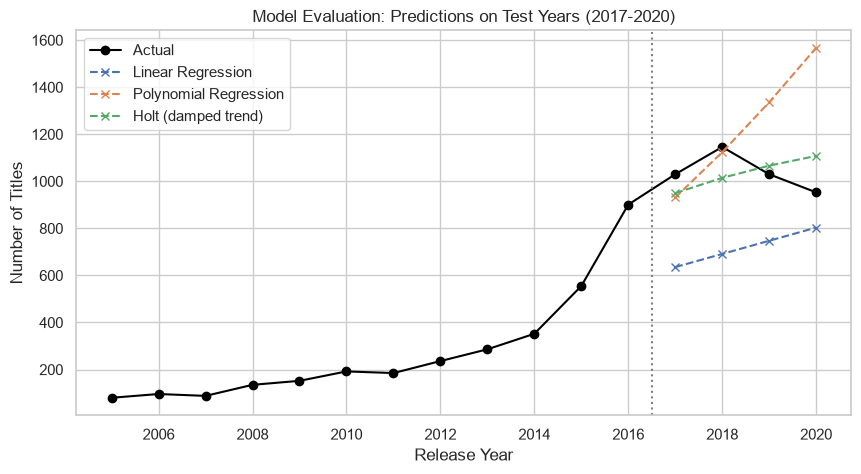

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(years, counts, marker="o", color="black", label="Actual")
for name, pred in test_preds.items():
    plt.plot(test_years, pred, marker="x", linestyle="--", label=name)
plt.axvline(2016.5, color="grey", linestyle=":")
plt.title("Model Evaluation: Predictions on Test Years (2017-2020)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.show()

## Step 4: Visualizing future predictions

In [11]:
best_model = results.loc[0, "Model"]
print("Best model:", best_model)

# Refit on all years (2005-2020) and forecast the next 5 years
future_years = np.arange(2021, 2026)
future = forecast(best_model, years, counts, future_years)
future_df = pd.DataFrame({"Year": future_years, "Forecast": future.round(0).astype(int)})
future_df

Best model: Holt (damped trend)


,Year,Forecast
0,2021,970
1,2022,974
2,2023,978
3,2024,980
4,2025,982


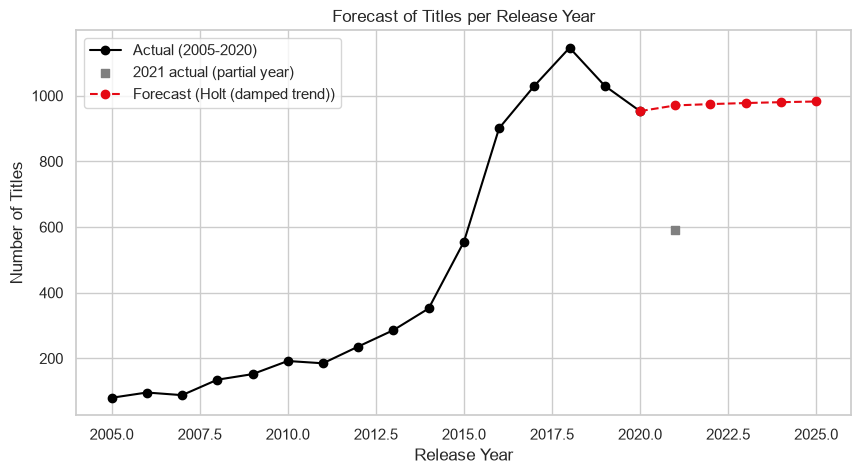

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(years, counts, marker="o", color="black", label="Actual (2005-2020)")
plt.scatter([2021], [yearly.loc[2021]], color="grey", marker="s", label="2021 actual (partial year)")
plt.plot(np.append(2020, future_years), np.append(counts[-1], future),
         marker="o", linestyle="--", color="#e50914", label=f"Forecast ({best_model})")
plt.title("Forecast of Titles per Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.show()

## Step 5: Interpret results

- **Trend:** The number of titles per release year grew very fast from 2014 to 2016 (+58% in 2015 and +62% in 2016), peaked in **2018 with 1,146 titles**, and has declined since (1,030 in 2019 and 953 in 2020).
- **Best model:** Holt's damped-trend smoothing was the most accurate on the test years (MAE about 101, RMSE about 111). Linear and Polynomial Regression were off by more than 250 titles on average, because they keep extending the 2014-2016 growth even though the trend flattened and turned down after 2018.
- **Forecast:** The best model expects roughly **970-980 titles per release year** for 2021-2025, which means stable content volume rather than another growth phase. The 2021 value of 592 in the data is not a decline, because that year is only partly covered (data ends in September 2021).
- **Limitations:** The data only covers titles on Netflix, not all films and shows produced. Only 16 yearly points are used, and recent years may be under-counted because of catalogue timing, so the forecast should be seen as a rough indication.